# Análisis de Tests de Perlin Noise

Este notebook combina los tests de uniformidad, avalancha y patrones para el generador de hashes usado en el ruido Perlin.
> **ADVERTENCIA:** La ejecución de estos tests es un proceso intensivo que requiere de un tiempo considerable. Como referencia, en un procesador Ryzen 7 5700X utilizando todos los hilos, la ejecución tomó más de 2 horas.

In [32]:
import re
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
import numpy as np
from scipy.stats import chi2, binom

In [33]:
FIGSIZE            = (16, 7.5)
TITLE_FONT_SIZE    = 24
SUBTITLE_FONT_SIZE = 20
LEGEND_FONT_SIZE   = 18
LABEL_FONT_SIZE    = 16
TICK_FONT_SIZE     = 16

COLOR_BLUE         = '#1B4182'
COLOR_LIGHT_GREEN  = '#90BE6D'
COLOR_GREEN        = "#2FAE53"
COLOR_YELLOW       = '#F9C74F'
COLOR_ORANGE       = '#F9844A'
COLOR_RED          = '#C0392B'

GRAY_DARK          = '#6E6E6E'
GRAY               = '#C0C0C0'
GRAY_LIGHT         = '#D0D0D0'
GRAY_LIGHTER       = '#E0E0E0'


plt.rc('font',   size=LABEL_FONT_SIZE)
plt.rc('axes',   titlesize=TITLE_FONT_SIZE, labelsize=LABEL_FONT_SIZE)
plt.rc('xtick',  labelsize=TICK_FONT_SIZE)
plt.rc('ytick',  labelsize=TICK_FONT_SIZE)
plt.rc('legend', fontsize=LEGEND_FONT_SIZE)
plt.rc('figure', titlesize=TITLE_FONT_SIZE)

HASH_FUNCTION = "rapidhash"

## 0. Compilación de los tests

Precompilamos todos los test

In [34]:
print("Compilando uniformity_test...")
cmd = ["zig", "build", "--release=fast"]
subprocess.run(cmd, check=True)
print(' '.join(cmd))

Compilando uniformity_test...
zig build --release=fast


## 1. Test de Uniformidad

Analiza si la distribución de valores generados por el hash es uniforme.

### 1.1 Extracción de Datos

Compilación y ejecución del test C para obtención de métricas (frecuencias, entropía, Chi-cuadrado).

In [35]:
uniformity_output_file = Path("logs/uniformity_output_64b.txt")
uniformity_output_file.parent.mkdir(parents=True, exist_ok=True)

UNIFORMITY_SAMPLES = 100_000_000
LOG_START_INDEX = 100
LOG_FACTOR = 100 ** (1/100)
SEED = 123456789

print("\nEjecutando test...")
cmd = ["./zig-out/bin/uniformity_64b", str(UNIFORMITY_SAMPLES), str(LOG_START_INDEX), str(LOG_FACTOR), str(SEED), HASH_FUNCTION]
print(' '.join(cmd))

result = subprocess.run(cmd, text=True, check=True, capture_output=True)
data_uniformity = result.stdout
uniformity_output_file.write_text(data_uniformity)


Ejecutando test...
./zig-out/bin/uniformity_64b 100000000 100 1.0471285480508996 123456789 rapidhash


22804

#### 1.1.1 Datos en bruto obtenidos

In [36]:
data_uniformity.strip().splitlines()[:5]

['{000000000000100, 65436.00, 65436.00, 65436.00, 65436.00, 6.64385619}',
 '{000000000000104, 65432.00, 65432.00, 65432.00, 65432.00, 6.70043972}',
 '{000000000000108, 65428.00, 65428.00, 65428.00, 65428.00, 6.75488750}',
 '{000000000000113, 65423.00, 65423.00, 65423.00, 65423.00, 6.82017896}',
 '{000000000000118, 65418.00, 65418.00, 65418.00, 65418.00, 6.88264305}']

In [37]:
data_uniformity.strip().splitlines()[-32:-27]

['{000000040822192, 66070.24, 65749.59, 65175.61, 65946.10, 15.99883819}',
 '{000000042746082, 66064.71, 65972.84, 65055.70, 65887.63, 15.99889031}',
 '{000000044760642, 66144.46, 66049.38, 64908.13, 65940.67, 15.99894001}',
 '{000000046870146, 65942.85, 66126.58, 64854.55, 66179.22, 15.99898747}',
 '{000000049079067, 65831.34, 65943.60, 64789.41, 66107.96, 15.99903464}']

### 1.2 Refinado de Datos

Procesamiento de salida textual a estructuras numéricas ($f_{abs}$, $\chi^2$, $H$).

In [38]:
frequencies_regex = re.compile(r'(\d+): (\d+)')
frequency_matches = frequencies_regex.findall(data_uniformity)

# Formato: {Total, Chi2_W0, Chi2_W1, Chi2_W2, Chi2_W3, AvgEntropy}
metrics_log_regex = re.compile(r'\{(\d+), ([\d.]+), ([\d.]+), ([\d.]+), ([\d.]+), ([\d.]+)\}')
metrics_matches = metrics_log_regex.findall(data_uniformity)

f_abs = [int(value) for _, value in frequency_matches]

chi2_log = [(int(idx), [float(c0), float(c1), float(c2), float(c3)]) 
            for idx, c0, c1, c2, c3, _ in metrics_matches]

entropy_log = [(int(idx), float(ent)) for idx, _, _, _, _, ent in metrics_matches]

### 1.3 Visualización de Datos

#### 1.3.1 Distribución de Frecuencias y Desviaciones ($\delta_{rel}$)

Desviación relativa porcentual por valor de salida (0-255).

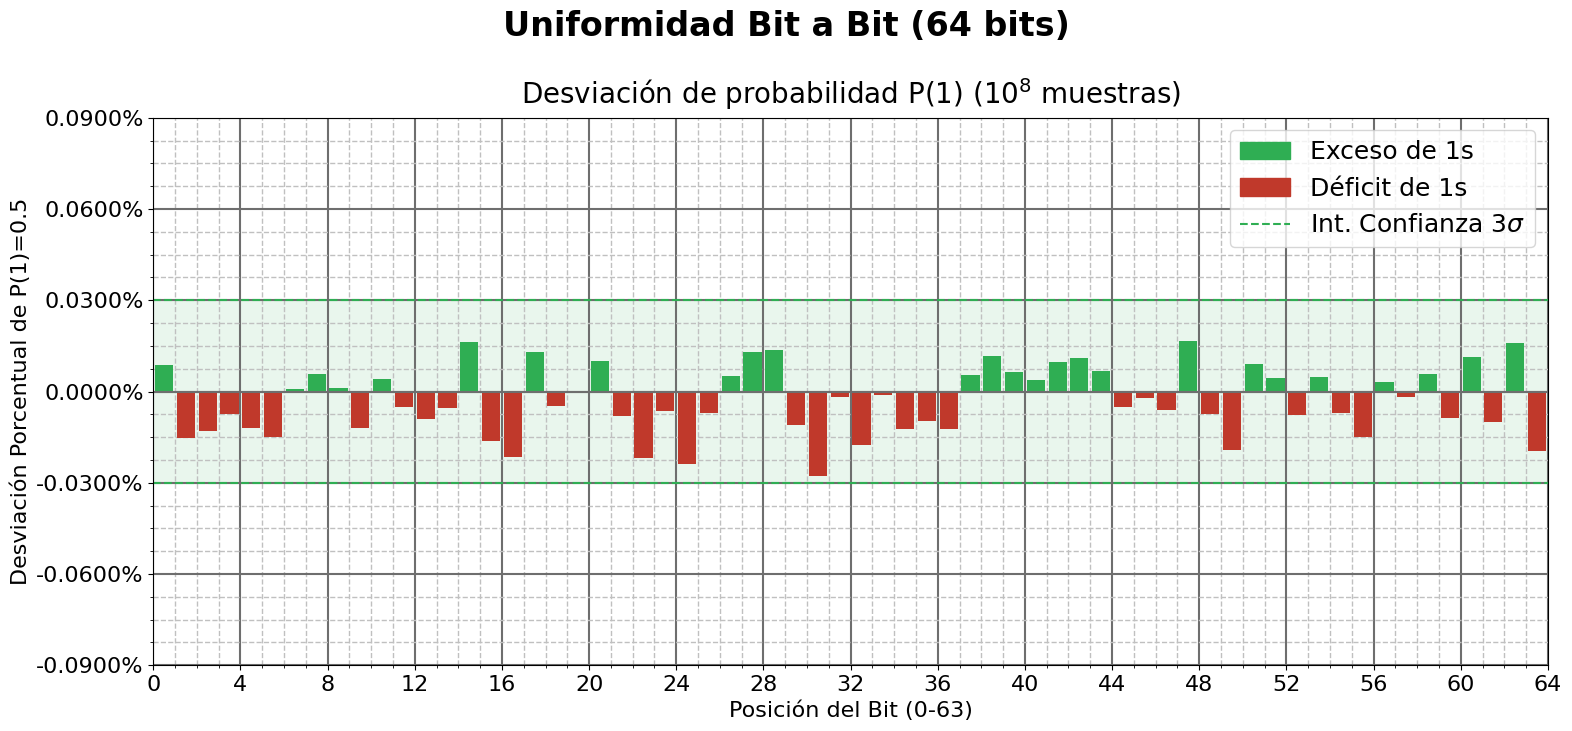

In [39]:
N = chi2_log[-1][0]
f_exp = N / 2.0
delta_rel = [(f - f_exp) / f_exp * 100 for f in f_abs]

bar_centers = [i + 0.5 for i in range(len(f_abs))]
sigma_3_pct = 300.0 / np.sqrt(N)
y_limit = 3 * sigma_3_pct

fig, ax = plt.subplots(figsize=FIGSIZE)

# 1. Ejes
ax.set_xlim(0, 64)
ax.set_ylim(-y_limit, y_limit)
ax.set_xlabel('Posición del Bit (0-63)')
ax.set_ylabel('Desviación Porcentual de P(1)=0.5')

# 2. Ticks
ax.set_xticks(range(0, 65, 4))
ax.set_xticklabels([f'{x}' for x in range(0, 65, 4)])

yticks = np.linspace(-y_limit, y_limit, 7)
ax.set_yticks(yticks)
ax.set_yticklabels([f'{y:.4f}%' for y in yticks])

ax.minorticks_on()
ax.xaxis.set_minor_locator(plt.MultipleLocator(1))
ax.xaxis.set_minor_formatter(plt.NullFormatter())

# 3. Rejilla
ax.grid(which='major', axis='both', linestyle='-', color=GRAY_DARK, linewidth=1.5)
ax.grid(which='minor', axis='both', linestyle='--', color=GRAY, linewidth=1)

# 4. Títulos
fig.suptitle('Uniformidad Bit a Bit (64 bits)', fontweight='bold')
ax.set_title(f'Desviación de probabilidad P(1) (${10}^{{{np.log10(N):.0f}}}$ muestras)',
             fontsize=SUBTITLE_FONT_SIZE, pad=10)

# 5. Elementos principales
bar_colors = [COLOR_GREEN if d > 0 else COLOR_RED for d in delta_rel]
ax.bar(bar_centers, delta_rel, color=bar_colors, width=5/6, zorder=2)
ax.axhline(y=0, color=GRAY_DARK, linestyle='-', linewidth=1.5)

ax.axhline(y=sigma_3_pct, color=COLOR_GREEN, linestyle='--', linewidth=1.5)
ax.axhline(y=-sigma_3_pct, color=COLOR_GREEN, linestyle='--', linewidth=1.5)
ax.fill_between([-1, 64], -sigma_3_pct, sigma_3_pct, color=COLOR_GREEN, alpha=0.1)

positive_patch = mpatches.Patch(color=COLOR_GREEN, label='Exceso de 1s')
negative_patch = mpatches.Patch(color=COLOR_RED, label='Déficit de 1s')
confidence_line = plt.Line2D([0], [0], color=COLOR_GREEN, linestyle='--',
                             label='Int. Confianza 3$\\sigma$')
ax.legend(handles=[positive_patch, negative_patch, confidence_line], loc='upper right')

plt.tight_layout()
plt.show()

#### 1.3.2 Convergencia del Test Chi-Cuadrado ($\chi^2$)

Evolución de $\chi^2$ respecto al número de muestras $N$. Bandas de confianza para distribución uniforme.

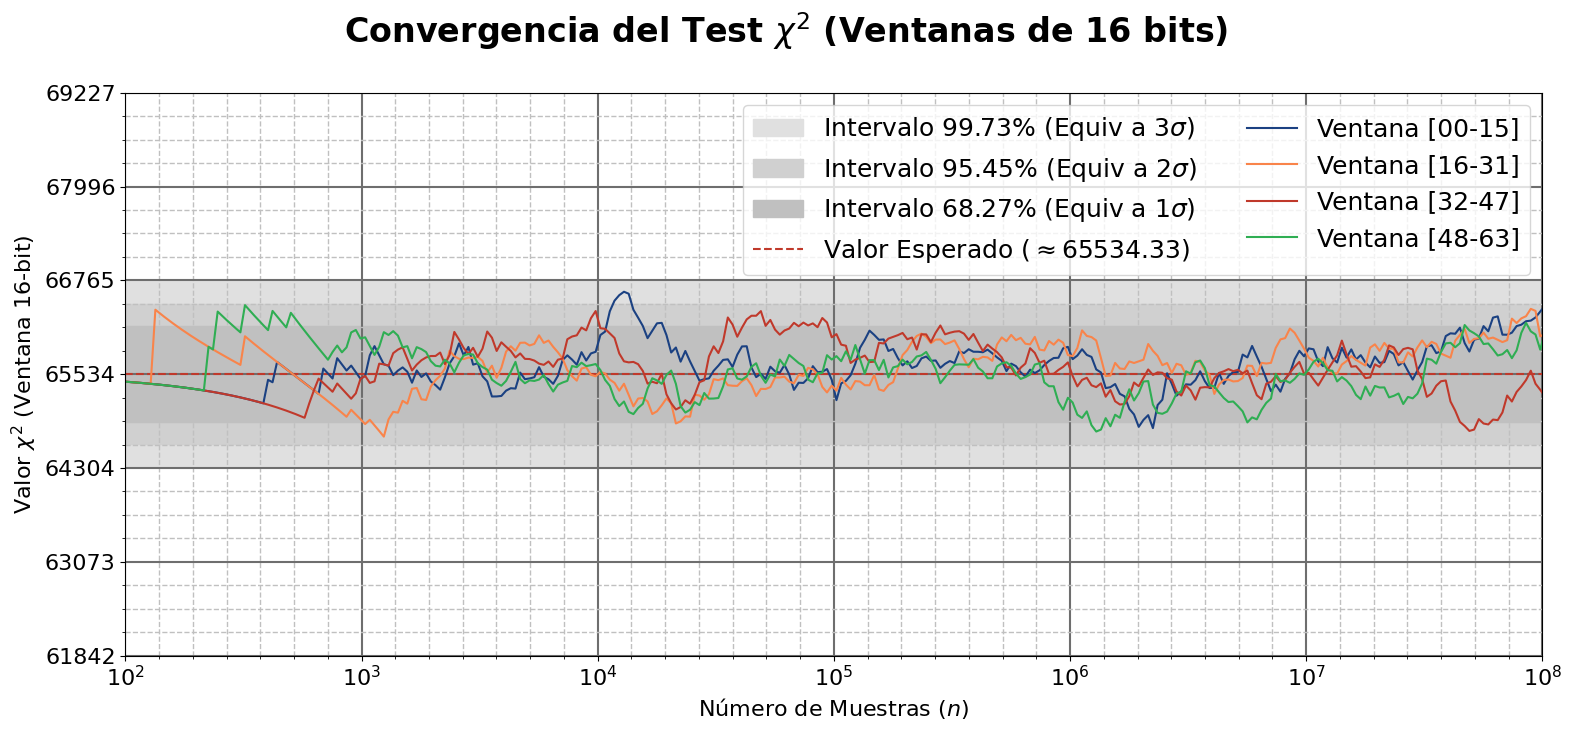

In [40]:
n_points = [x for x, _ in chi2_log]
chi2_values = np.array([vals for _, vals in chi2_log])

degrees_of_freedom = 2**16 - 1

thresholds = [
    (0.0027, GRAY_LIGHTER, '99.73% (Equiv a 3$\\sigma$)'),
    (0.0455, GRAY_LIGHT,   '95.45% (Equiv a 2$\\sigma$)'),
    (0.3173, GRAY,         '68.27% (Equiv a 1$\\sigma$)'),
]

fig, ax = plt.subplots(figsize=FIGSIZE)

# 1. Ejes
ax.set_xscale('log', base=10)
ax.set_xlim(n_points[0], n_points[-1])

# Escala Y: el intervalo 3σ (con Bonferroni) ocupa el tercio central
y_avg = chi2.ppf(0.5, degrees_of_freedom)
p_low_3s = thresholds[0][0] / 8
val_low_3s = chi2.ppf(p_low_3s, degrees_of_freedom)
val_high_3s = chi2.ppf(1 - p_low_3s, degrees_of_freedom)

margin_3s = (val_high_3s - val_low_3s) / 2.0
y_limit = margin_3s * 3.0

y_min = y_avg - y_limit
y_max = y_avg + y_limit

ax.set_ylim(y_min, y_max)
ax.set_xlabel('Número de Muestras ($n$)')
ax.set_ylabel('Valor $\\chi^2$ (Ventana 16-bit)')

# 2. Ticks
min_pow = int(np.floor(np.log10(n_points[0])))
max_pow = int(np.ceil(np.log10(n_points[-1])))
pow_range = range(min_pow, max_pow + 1)

ax.set_xticks([10**i for i in pow_range])
ax.set_xticklabels([fr'$10^{{{i}}}$' for i in pow_range])

ax.minorticks_on()
ax.xaxis.set_minor_locator(plt.FixedLocator([10**(min_pow + i/7) for i in range((max_pow - min_pow) * 7)]))
ax.xaxis.set_minor_formatter(plt.NullFormatter())

yticks = np.linspace(y_min, y_max, 7)
ax.set_yticks(yticks)
ax.set_yticklabels([f'{y:.0f}' for y in yticks])

# 3. Rejilla
ax.grid(which='major', linestyle='-', linewidth=1.5, color=GRAY_DARK)
ax.grid(which='minor', linestyle='--', linewidth=1, color=GRAY)

# 4. Títulos
fig.suptitle('Convergencia del Test $\\chi^2$ (Ventanas de 16 bits)', fontweight='bold')

# 5. Elementos principales
for alpha, color, label in thresholds:
    p_low = alpha / 8
    val_low = chi2.ppf(p_low, degrees_of_freedom)
    val_high = chi2.ppf(1 - p_low, degrees_of_freedom)
    ax.fill_between(n_points, val_low, val_high, color=color, label=f'Intervalo {label}')

ax.axhline(y_avg, color=COLOR_RED, linestyle='--', linewidth=1.5,
           label=f'Valor Esperado ($\\approx${y_avg:.2f})')

window_labels = ['Ventana [00-15]', 'Ventana [16-31]', 'Ventana [32-47]', 'Ventana [48-63]']

colors = [COLOR_BLUE, COLOR_ORANGE, COLOR_RED, COLOR_GREEN]
for i in range(4):
    ax.plot(n_points, chi2_values[:, i], label=window_labels[i], color=colors[i], linewidth=1.5)

ax.legend(loc='upper right', ncol=2)

plt.tight_layout()
plt.show()

#### 1.3.3 Convergencia de la Entropía de Shannon ($H$)

Evolución de la Entropía $H$ vs muestras $N$. Referencia teórica $H_{max} = 16.0$ bits.

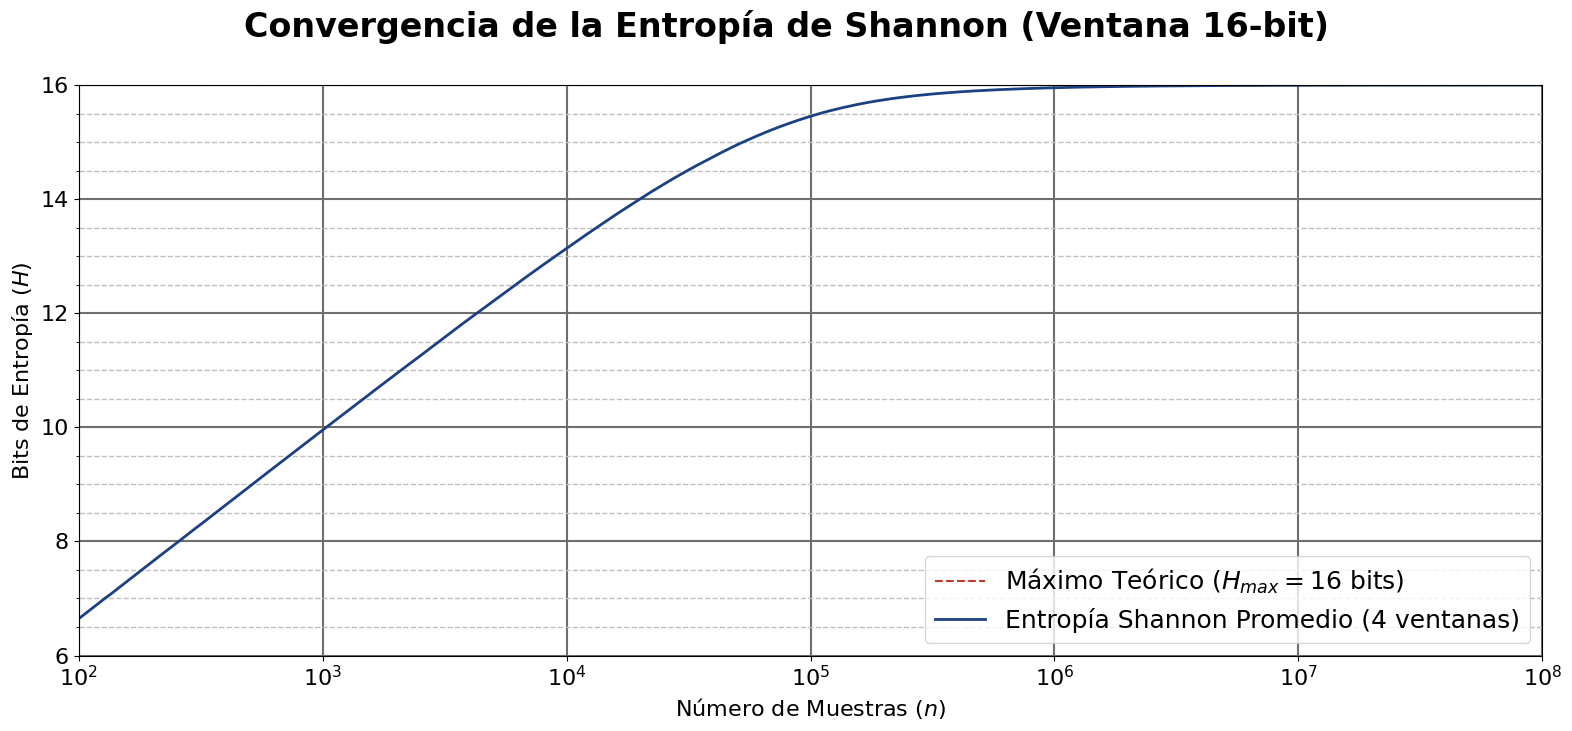

In [41]:
n_points  = [x for x, _ in chi2_log]
H_shannon = [y for _, y in entropy_log]

fig, ax = plt.subplots(figsize=FIGSIZE)

# 1. Ejes
ax.set_xscale('log', base=LOG_FACTOR)
ax.set_xlim(n_points[0], n_points[-1])

ax.set_ylim(6, 16)

ax.set_xlabel('Número de Muestras ($n$)')
ax.set_ylabel('Bits de Entropía ($H$)')

# 2. Ticks
min_pow = int(np.floor(np.log10(n_points[0])))
max_pow = int(np.ceil(np.log10(n_points[-1])))
pow_range = range(min_pow, max_pow + 1)

ax.set_xticks([10**i for i in pow_range])
ax.set_xticklabels([fr'$10^{{{i}}}$' for i in pow_range])

ax.minorticks_on()
ax.xaxis.set_minor_formatter(plt.NullFormatter())

# 3. Rejilla
ax.grid(which='major', linestyle='-', linewidth=1.5, color=GRAY_DARK)
ax.grid(which='minor', linestyle='--', linewidth=1, color=GRAY)

# 4. Títulos
fig.suptitle('Convergencia de la Entropía de Shannon (Ventana 16-bit)', fontweight='bold')

# 5. Elementos principales
ax.axhline(16.0, color=COLOR_RED, linestyle='--', linewidth=1.5,
           label='Máximo Teórico ($H_{max} = 16$ bits)')
ax.plot(n_points, H_shannon, label='Entropía Shannon Promedio (4 ventanas)',
        color=COLOR_BLUE, linewidth=2)

ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

## 2. Test de Avalancha

Análisis Sensibilidad de entrada/salida (Efecto Avalancha). Objetivo: cambio de ~50% bits salida ante cambio de 1 bit entrada.

### 2.1 Extracción de Datos


Generación de métricas de avalancha: cambios en salida vs flips de 1 bit en $S, X, Y$.

In [42]:
AVALANCHE_SAMPLES = 1_000_000
AVALANCHE_SEED = 123456789

avalanche_output_file = Path("logs/avalanche_64b_output.txt")
avalanche_output_file.parent.mkdir(parents=True, exist_ok=True)

cmd = ["./zig-out/bin/avalanche_64b", str(AVALANCHE_SAMPLES), str(AVALANCHE_SEED), HASH_FUNCTION]
print(" ".join(cmd))

result = subprocess.run(cmd, capture_output=True, text=True, check=True)
data_avalanche = result.stdout
avalanche_output_file.write_text(data_avalanche)

./zig-out/bin/avalanche_64b 1000000 123456789 rapidhash


92654

#### 2.1.1 Datos en bruto obtenidos

In [43]:
data_avalanche.strip().splitlines()[:16]

['000, 000000000000, 000000000000, 000000000000',
 '001, 000000000000, 000000000000, 000000000000',
 '002, 000000000000, 000000000000, 000000000000',
 '003, 000000000000, 000000000000, 000000000000',
 '004, 000000000000, 000000000000, 000000000000',
 '005, 000000000000, 000000000000, 000000000000',
 '006, 000000000000, 000000000000, 000000000000',
 '007, 000000000000, 000000000000, 000000000000',
 '008, 000000000000, 000000000000, 000000000000',
 '009, 000000000001, 000000000000, 000000000000',
 '010, 000000000001, 000000000002, 000000000001',
 '011, 000000000001, 000000000002, 000000000002',
 '012, 000000000008, 000000000006, 000000000014',
 '013, 000000000043, 000000000053, 000000000051',
 '014, 000000000158, 000000000173, 000000000159',
 '015, 000000000567, 000000000593, 000000000515']

In [44]:
data_avalanche.strip().splitlines()[66:70]

['001: 000031994770, 000031998469, 000032000675 | S[500031,499968,499787,499484,499760,499445,500349,499642,500243,500213,500330,500676,500191,499708,500156,500466,499787,500291,500457,499737,499473,500525,500322,499994,500262,500258,499683,500279,499680,499659,499234,499352,499782,500074,500678,499628,500446,500299,500066,499858,499311,499939,499714,499623,500218,499876,500068,500313,499596,499945,499136,499776,499801,499846,499499,499784,499895,499917,499894,500005,499501,499638,500061,499141] X[499939,499762,500926,499394,499864,500660,500345,499089,499473,500393,498947,500298,500417,499766,500491,499507,500909,500737,501346,498746,500531,500239,499652,500575,499157,499565,499938,499685,499865,499466,500259,500147,501208,500684,499900,499759,500467,500249,499156,499768,499296,500402,499662,499739,499862,499593,500080,499549,499770,500846,499409,499833,499037,500544,499913,499419,500027,499666,500397,499857,499772,500492,499707,500318] Y[499504,500166,498873,499715,499423,500358,4996

### 2.2 Refinado de Datos

Procesamiento: Frecuencias Hamming ($f_h$) y media cambios/bit ($\mu$).

In [45]:
dist_regex = re.compile(r'(\d+),\s+(\d+),\s+(\d+),\s+(\d+)')
dist_data = dist_regex.findall(data_avalanche)

sac_regex = re.compile(r'(\d+):\s+(\d+),\s+(\d+),\s+(\d+)\s+\|\s+S\[(.*?)\]\s+X\[(.*?)\]\s+Y\[(.*?)\]')
sac_matches = sac_regex.findall(data_avalanche)

f_h_s = [int(r[1]) for r in dist_data]
f_h_x = [int(r[2]) for r in dist_data]
f_h_y = [int(r[3]) for r in dist_data]
f_h_total = [s + x + y for s, x, y in zip(f_h_s, f_h_x, f_h_y)]

mu_flips_s = [int(r[1]) / AVALANCHE_SAMPLES for r in sac_matches]
mu_flips_x = [int(r[2]) / AVALANCHE_SAMPLES for r in sac_matches]
mu_flips_y = [int(r[3]) / AVALANCHE_SAMPLES for r in sac_matches]

# Matrices SAC (64x64): P(flip) por cada par (bit_entrada, bit_salida)
sac_matrix_s = np.array([list(map(int, r[4].split(','))) for r in sac_matches]) / AVALANCHE_SAMPLES
sac_matrix_x = np.array([list(map(int, r[5].split(','))) for r in sac_matches]) / AVALANCHE_SAMPLES
sac_matrix_y = np.array([list(map(int, r[6].split(','))) for r in sac_matches]) / AVALANCHE_SAMPLES

### 2.3 Visualización de Datos

#### 2.3.1 Análisis de la Distribución de Hamming y Efecto Avalancha

Comparación métricas observadas vs ideal teórico (Binomial, $\mu=32.0$).

In [46]:
mu_global = np.mean([mu_flips_s, mu_flips_x, mu_flips_y])

print(f"Promedio global de bits de salida girados ($\\mu$): {mu_global:.8f} (Ideal: 32.0)")
print(f"\tDesviación respecto al ideal: {abs(32.0 - mu_global):.8f}")
print("-" * 50)
print(f"Media S ($\\mu_s$): {np.mean(mu_flips_s):.8f}")
print(f"Media X ($\\mu_x$): {np.mean(mu_flips_x):.8f}")
print(f"Media Y ($\\mu_y$): {np.mean(mu_flips_y):.8f}")

Promedio global de bits de salida girados ($\mu$): 31.99993463 (Ideal: 32.0)
	Desviación respecto al ideal: 0.00006537
--------------------------------------------------
Media S ($\mu_s$): 32.00041942
Media X ($\mu_x$): 31.99929977
Media Y ($\mu_y$): 32.00008470


In [47]:
def plot_avalanche_effect(data, title):
    std_err = np.sqrt(64 * 0.5 * 0.5 / AVALANCHE_SAMPLES)
    margin = 3.0 * std_err
    ci_lower, ci_upper = 32.0 - margin, 32.0 + margin

    fig, ax = plt.subplots(figsize=FIGSIZE)

    # 1. Ejes
    ax.set_xlim(0, 64)
    y_min = 32.0 - margin * 3
    y_max = 32.0 + margin * 3
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel('Posición del bit de entrada $j$ (0-63)')
    ax.set_ylabel('$\\mu$ bits girados')

    # 2. Ticks
    ax.set_xticks(np.arange(0, 65, 4))

    yticks = np.linspace(y_min, y_max, 7)
    ax.set_yticks(yticks)
    ax.set_yticklabels([f'{y:.5f}' for y in yticks])

    ax.minorticks_on()
    ax.xaxis.set_minor_locator(plt.MultipleLocator(1))

    # 3. Rejilla
    ax.grid(which='major', linestyle='-', linewidth=1.5, color=GRAY_DARK)
    ax.grid(which='minor', linestyle='--', linewidth=1, color=GRAY)

    # 4. Títulos
    fig.suptitle(title, fontweight='bold')
    ax.set_title(f'Intervalo de confianza $3\\sigma \\approx 99.73\\%$ ($N=10^{{{int(np.log10(AVALANCHE_SAMPLES))}}}$)',
                 fontsize=SUBTITLE_FONT_SIZE, pad=10)

    # 5. Elementos principales
    ax.fill_between(range(65), ci_lower, ci_upper, color=COLOR_GREEN, alpha=0.2,
                    label='Zona de Aceptación (3$\\sigma$)')
    ax.axhline(y=32.0, color=COLOR_RED, linestyle='--', linewidth=1.5,
               label='Media Teórica ($\\mu=32.0$)')
    ax.stairs(list(data) + [data[-1]], baseline=None, color=COLOR_BLUE, linewidth=2,
                  zorder=2, label='Media Observada ($\\mu$)', alpha=0.8)

    ax.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

#### 2.3.2 Efecto Avalancha: Variando bits de $Seed$

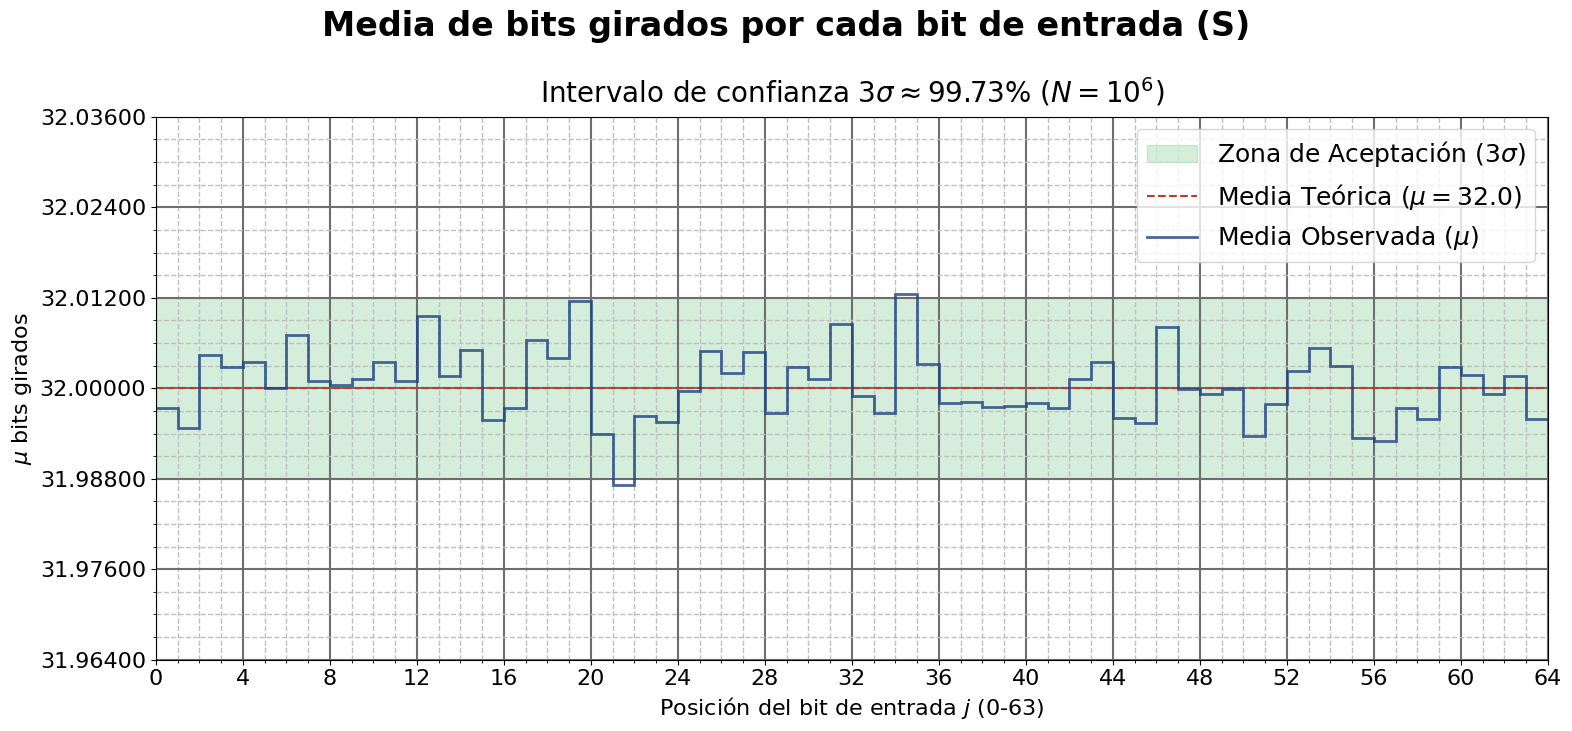

In [48]:
plot_avalanche_effect(mu_flips_s, "Media de bits girados por cada bit de entrada (S)")

#### 2.3.3 Efecto Avalancha: Variando bits de $X$


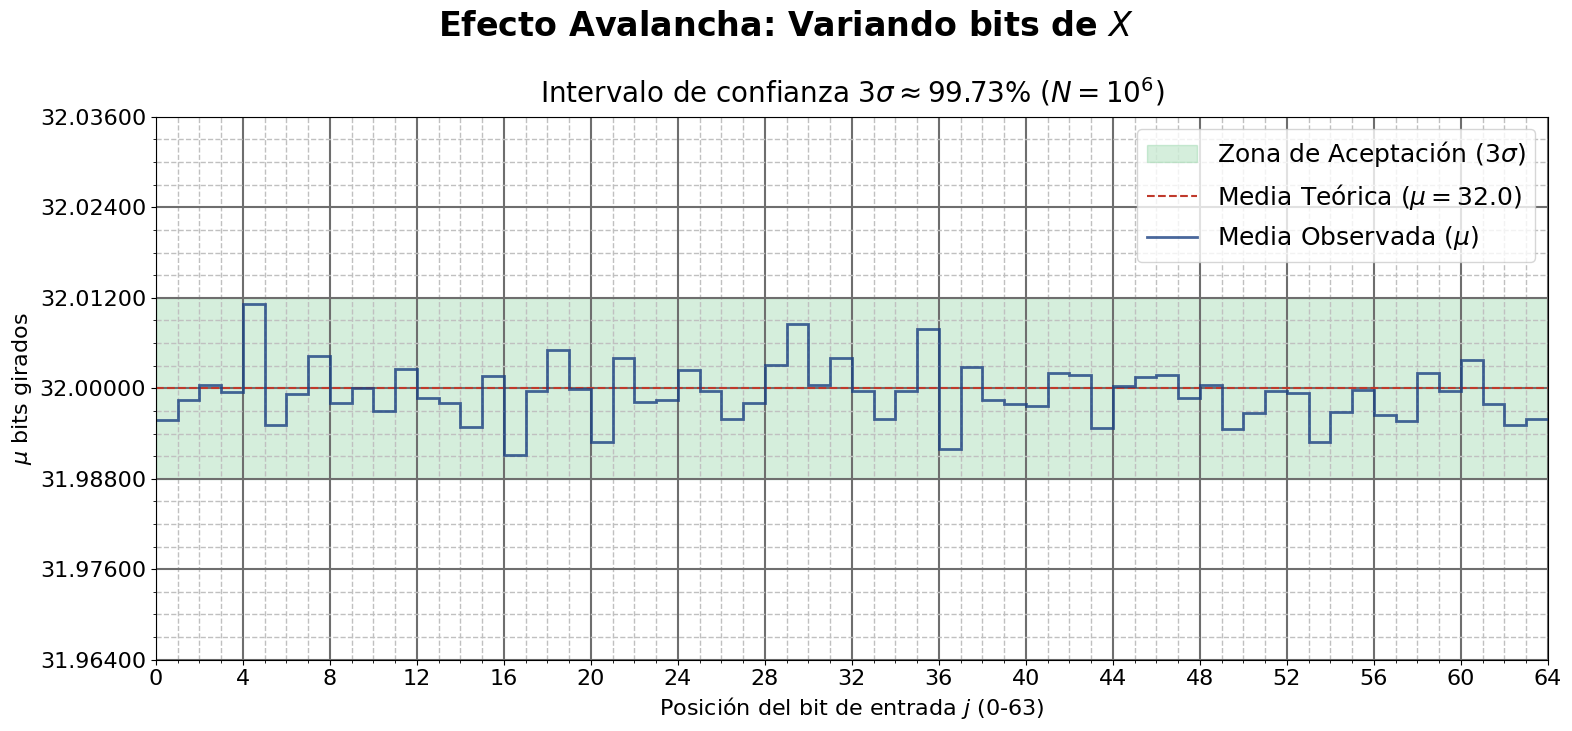

In [49]:
plot_avalanche_effect(mu_flips_x, 'Efecto Avalancha: Variando bits de $X$')

#### 2.3.4 Efecto Avalancha: Variando bits de $Y$

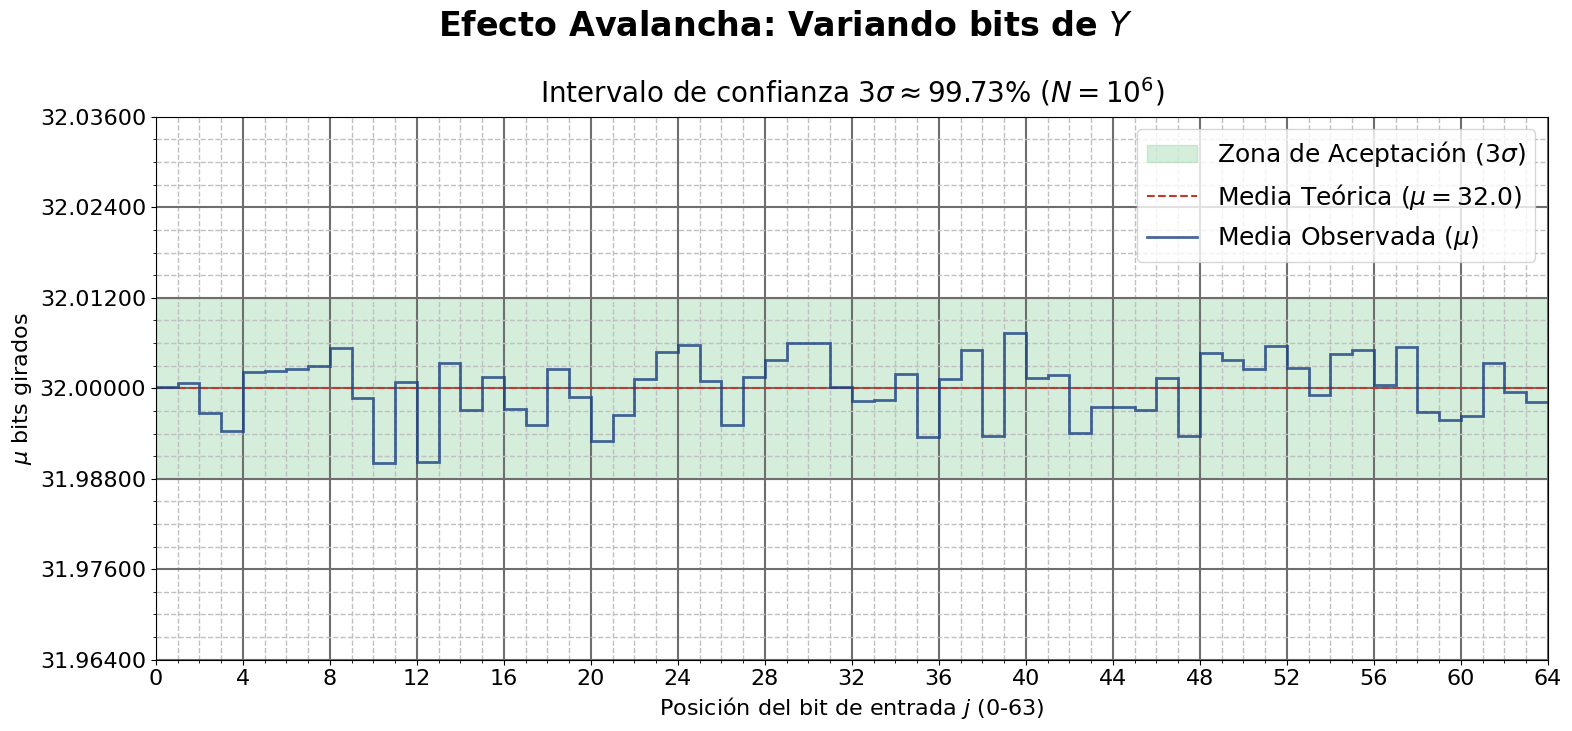

In [50]:
plot_avalanche_effect(mu_flips_y, 'Efecto Avalancha: Variando bits de $Y$')

#### 2.3.5 Distribución de Bits Cambiados (Distancia de Hamming $h$)

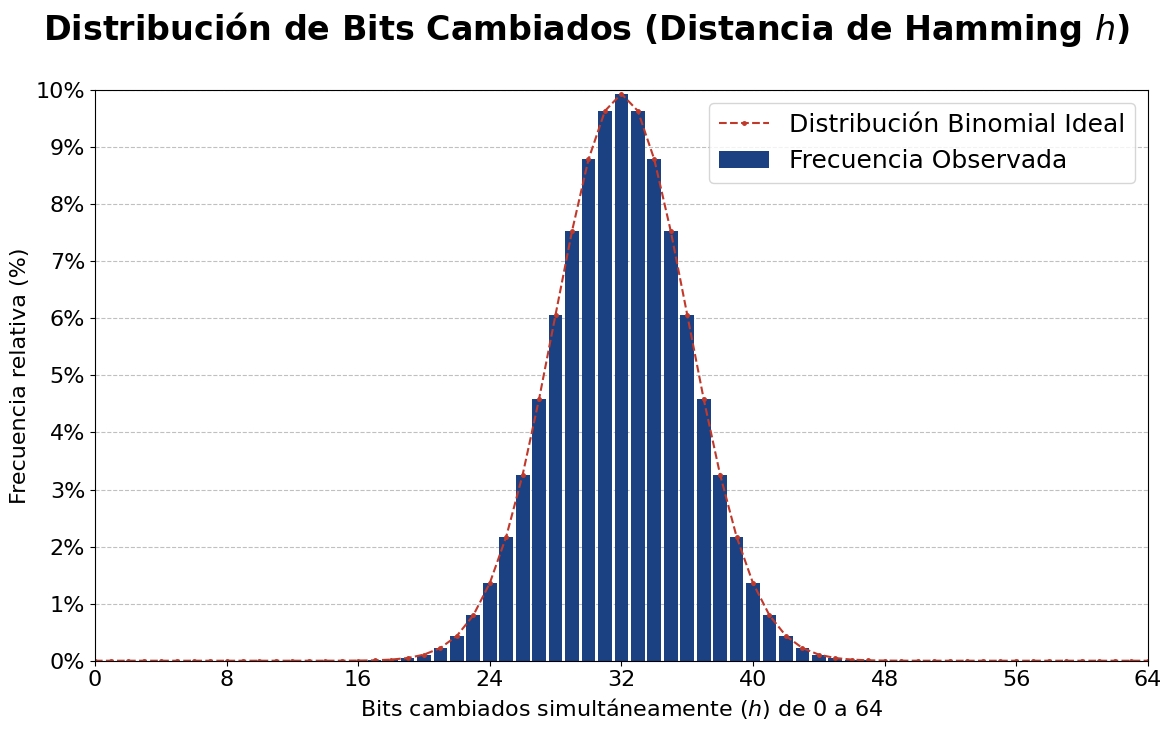

In [51]:
fig, ax = plt.subplots(figsize=(12, 7.5))

# 1. Ejes
h_vals = np.arange(len(f_h_total))
ax.set_xlabel('Bits cambiados simultáneamente ($h$) de 0 a 64')
ax.set_ylabel('Frecuencia relativa (%)')
ax.set_xlim(0, 64)
ax.set_ylim(0, 0.1)

# 2. Ticks
ax.set_xticks(range(0, 65, 8))
yticks_vals = np.linspace(0, 0.1, 11)
ax.set_yticks(yticks_vals)
ax.set_yticklabels([f'{y * 100:.0f}%' for y in yticks_vals])

# 3. Rejilla
ax.grid(axis='y', linestyle='--', color=GRAY)

# 4. Títulos
fig.suptitle('Distribución de Bits Cambiados (Distancia de Hamming $h$)', fontweight='bold')

# 5. Elementos principales
total_ensayos = 3 * 64 * AVALANCHE_SAMPLES
f_rel_total = np.array(f_h_total) / total_ensayos
dist_binomial = binom.pmf(h_vals, 64, 0.5)

ax.bar(h_vals, f_rel_total, width=5/6, color=COLOR_BLUE, label='Frecuencia Observada', zorder=2)
ax.plot(h_vals, dist_binomial, color=COLOR_RED, linestyle='--', marker='.',
        markersize=5, label='Distribución Binomial Ideal')

ax.legend()
plt.tight_layout()
plt.show()

#### 2.3.6 Análisis del Criterio de Avalancha Estricto (SAC)

Evaluación detallada de la independencia de bits.
*   **Izquierda:** Matriz $(i, j)$ donde varía S.
*   **Centro:** Matriz $(i, j)$ donde varía X.
*   **Derecha:** Matriz $(i, j)$ donde varía Y.

Cada celda representa la probabilidad de cambio en el bit de salida $j$ al invertir el bit de entrada $i$. El valor ideal es $0.5$ (verde). Desviaciones significativas (rojo) indican correlaciones no deseadas.

#### 2.3.7 Análisis Integral del SAC (S, X, Y)


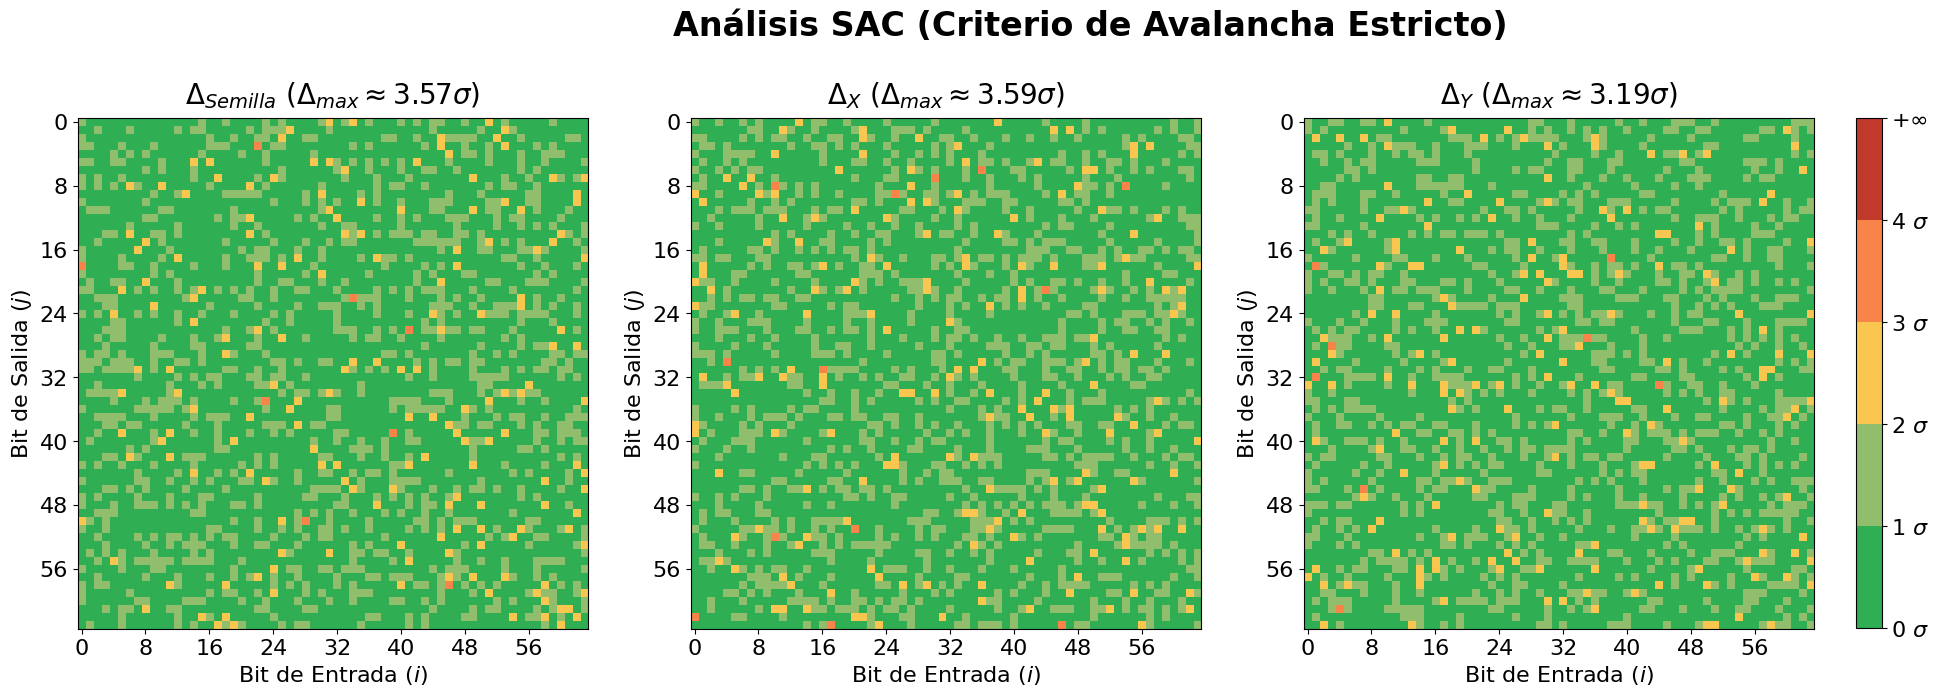

In [52]:
sac_configs = [
    (sac_matrix_s, '$\\Delta_{{Semilla}}$'),
    (sac_matrix_x, '$\\Delta_{{X}}$'),
    (sac_matrix_y, '$\\Delta_{{Y}}$')
]

fig, axes = plt.subplots(1, len(sac_configs), figsize=(27, 7.5))
axes = axes.flatten()

std_err_bit = 0.5 / np.sqrt(AVALANCHE_SAMPLES)
cmap = ListedColormap([COLOR_GREEN, COLOR_LIGHT_GREEN, COLOR_YELLOW, COLOR_ORANGE, COLOR_RED])

for i, (matrix, title) in enumerate(sac_configs):
    ax = axes[i]
    z_scores = np.abs(matrix.T - 0.5) / std_err_bit
    z_mapped = np.digitize(z_scores, [1, 2, 3, 4, 100])
    dev_max_sigma = np.max(z_scores)

    # 1. Ejes
    ax.set_xlim(-0.5, 63.5)
    ax.set_ylim(63.5, -0.5)
    ax.set_xlabel('Bit de Entrada ($i$)')
    ax.set_ylabel('Bit de Salida ($j$)')

    # 2. Ticks
    ax.set_xticks(np.arange(0, 64, 8))
    ax.set_yticks(np.arange(0, 64, 8))

    # 3. Títulos
    ax.set_title(f"{title} ($\\Delta_{{max}} \\approx {dev_max_sigma:.2f}\\sigma$)",
                 fontsize=SUBTITLE_FONT_SIZE, pad=10)

    # 4. Elementos principales
    im = ax.imshow(z_mapped, cmap=cmap, vmin=0, vmax=5, aspect='equal', zorder=2)

# 5. Título y leyenda global
fig.suptitle('Análisis SAC (Criterio de Avalancha Estricto)', fontweight='bold')

cbar = fig.colorbar(im, ax=axes.tolist(), pad=0.02, shrink=883/1000)
cbar.set_ticks([0, 1, 2, 3, 4, 5])
cbar.set_ticklabels(['0 $\\sigma$', '1 $\\sigma$', '2 $\\sigma$', '3 $\\sigma$', '4 $\\sigma$', '$+\\infty$'])

plt.show()

## 3. Test de Patrones

Evaluación dual para detectar repeticiones no deseadas:
1. **Dominio Espacial:** Inspección visual directa para identificar artefactos geométricos.
2. **Dominio de Frecuencia (FFT):** Verificación matemática de la ausencia de periodicidad oculta.

### 3.1 Extracción de Datos

Generación de arrays binarios de secciones 2D (planos XY, XS, SY).

In [53]:
PATTERN_S = 0xE_DC_BA_98_76_54_32_10
PATTERN_X = 0x1_23_45_67_89_AB_CD_EF
PATTERN_Y = 0x0_10_10_10_10_10_10_10
PATTERN_SIZE = 256
PATTERN_OUT_DIR = Path("logs")
PATTERN_OUT_DIR.mkdir(parents=True, exist_ok=True)

print("\nEjecutando test...")
cmd = ["./zig-out/bin/pattern_64b", str(PATTERN_S), str(PATTERN_X), str(PATTERN_Y), str(PATTERN_SIZE), str(PATTERN_OUT_DIR), HASH_FUNCTION]

subprocess.run(cmd, check=True)
print(' '.join(cmd))


Ejecutando test...
./zig-out/bin/pattern_64b 1070935975390360080 81985529216486895 4521260802379792 256 logs rapidhash


In [54]:
def plot_matrix_comparison(data_list, subplot_titles, main_title, axes_labels, cbar_label=None):
    fig, axes = plt.subplots(1, 3, figsize=(24, 6))

    for i, data in enumerate(data_list):
        ax = axes[i]

        # 1. Ejes
        ax.set_xlabel(axes_labels[i][0])
        ax.set_ylabel(axes_labels[i][1])

        # 2. Ticks
        size = data.shape[0]
        ticks = np.linspace(0, size, 9)
        
        ax.set_xticks(ticks)
        ax.set_yticks(ticks)

        ax.set_xticklabels([f'{int(t)}' for t in ticks])
        ax.set_yticklabels([f'{int(t)}' for t in ticks])

        # 3. Títulos
        ax.set_title(subplot_titles[i], fontsize=SUBTITLE_FONT_SIZE)

        # 4. Elementos principales
        im = ax.imshow(data, cmap='gray', origin='lower')

    # 5. Título y leyenda global
    fig.suptitle(main_title, fontweight='bold')
    fig.colorbar(im, ax=axes.tolist(), shrink=0.950, aspect=10, pad=0.04, label=cbar_label)

    plt.show()

### 3.2 Inspección Visual (Dominio Espacial)

Visualización directa de los cortes generados (ficheros binarios `pattern_*.bin`).

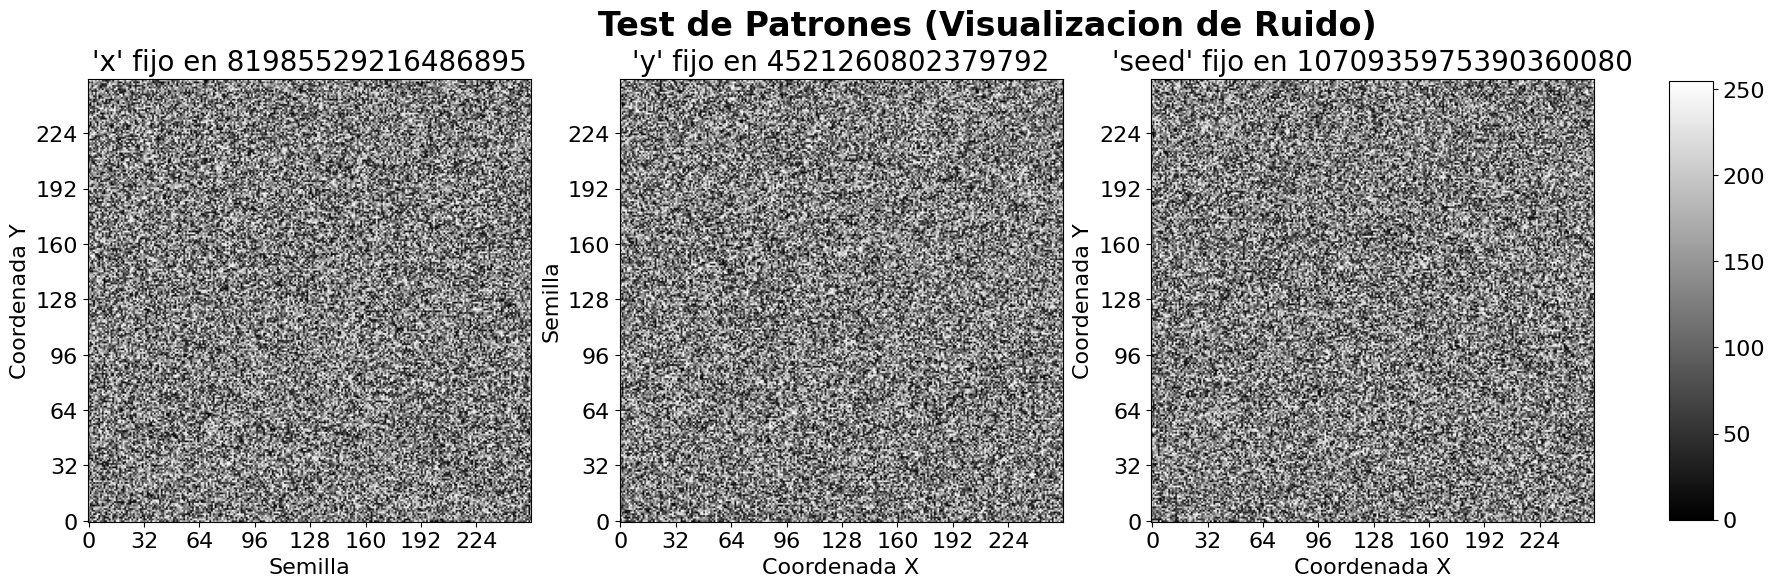

In [55]:
configs = [
    ('x', PATTERN_X, 'pattern_sy.bin', "Semilla", "Coordenada Y"),
    ('y', PATTERN_Y, 'pattern_xs.bin', "Coordenada X", "Semilla"),
    ('seed', PATTERN_S, 'pattern_xy.bin', "Coordenada X", "Coordenada Y")
]

def load_pattern_bin_u64(path, size):
    raw = np.fromfile(path, dtype=np.uint64)
    expected = size * size
    if raw.size != expected:
        raise ValueError(f"Tamaño invalido en {path}: {raw.size} elementos, esperado {expected}.")
    return raw.reshape((size, size))

pattern_data_u64 = [load_pattern_bin_u64(PATTERN_OUT_DIR / c[2], PATTERN_SIZE) for c in configs]

# Para comparabilidad con la version PNG previa, usamos el byte mas significativo de cada hash.
pattern_data_list = [((arr >> 56) & 0xFF).astype(np.uint8) for arr in pattern_data_u64]
subplot_titles = [f"'{c[0]}' fijo en {c[1]}" for c in configs]
spatial_labels = [(c[3], c[4]) for c in configs]

plot_matrix_comparison(pattern_data_list, subplot_titles,
                       "Test de Patrones (Visualizacion de Ruido)",
                       spatial_labels)

### 3.3 Análisis Espectral (FFT)

Transformada de Fourier 2D para analizar el dominio de la frecuencia.

**Objetivo:** Verificar la ausencia de periodicidad. Un buen ruido aleatorio (ruido blanco) debe mostrar una distribución de energía uniforme (espectro plano) sin picos dominantes o patrones geométricos claros (estrellas, líneas fuertes) que revelarían regularidades en el hash.

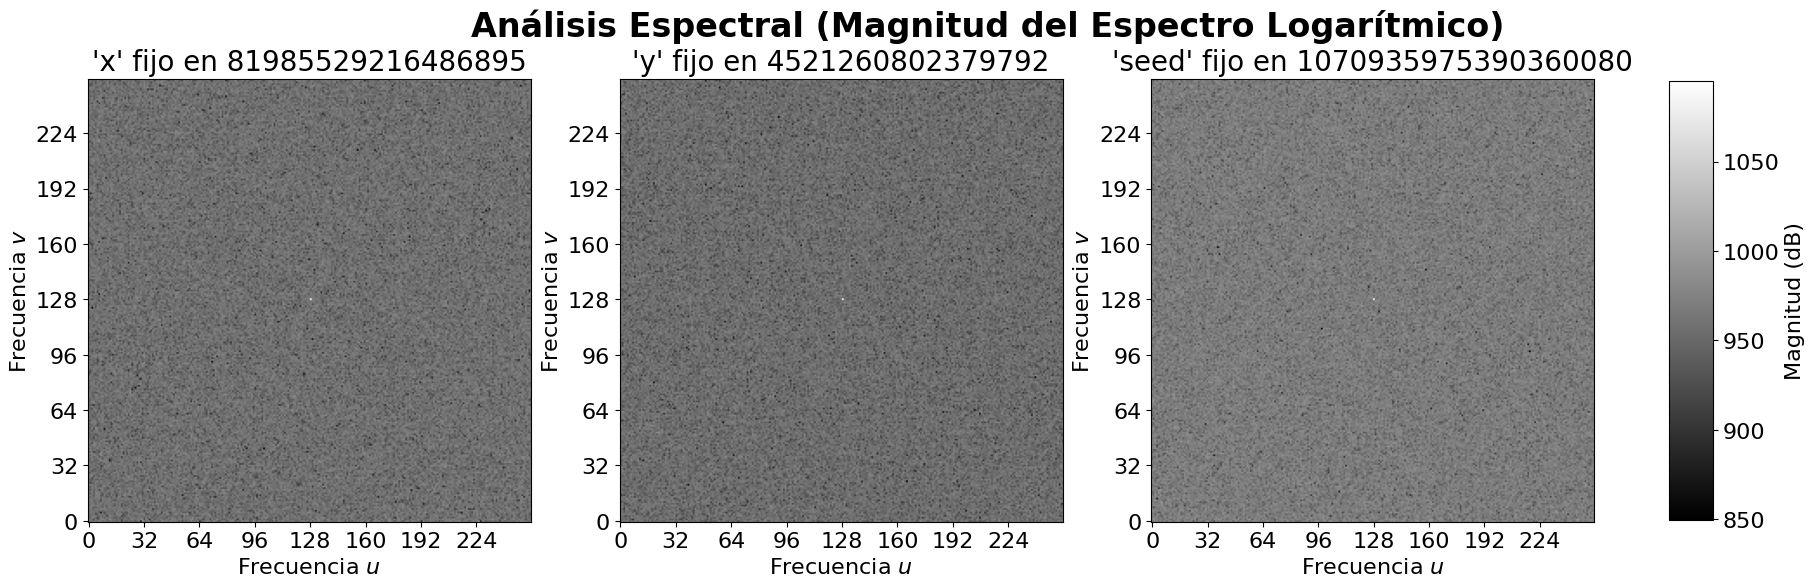

In [56]:
fft_data_list = []
for data in pattern_data_u64:
    f_shift = np.fft.fftshift(np.fft.fft2(data))
    fft_data_list.append(20 * np.log(np.abs(f_shift) + 1e-9))

fft_labels = [("Frecuencia $u$", "Frecuencia $v$")] * 3

plot_matrix_comparison(fft_data_list, subplot_titles,
                       "Análisis Espectral (Magnitud del Espectro Logarítmico)",
                       fft_labels,
                       cbar_label="Magnitud (dB)")

## 4. Test de Throughput (Monohilo)

Este apartado mide el coste de `hash(seed, x, y)` en ciclos por llamada.
El benchmark esta disenado para reducir ruido de microbenchmarking:

- ejecuta una fase de warm-up antes de medir,
- mide lotes grandes y divide por el numero de hashes,
- repite la medicion varias veces,
- usa la mediana como estadistico principal,
- no incluye `xorshift64` en la region medida.

### 4.1 Extracción de Datos

Compilación y ejecución del benchmark C para obtención de métricas de rendimiento (ciclos/hash).

In [57]:
throughput_output_file = Path("logs/throughput_output_64b.txt")
throughput_output_file.parent.mkdir(parents=True, exist_ok=True)

THROUGHPUT_REPS = 500
THROUGHPUT_BATCH = 16_000
THROUGHPUT_SEED = 42

print("\nEjecutando test...")
cmd = ["./zig-out/bin/throughput_64b", str(THROUGHPUT_REPS), str(THROUGHPUT_BATCH), str(THROUGHPUT_SEED), HASH_FUNCTION]
print(' '.join(cmd))

result = subprocess.run(cmd, capture_output=True, text=True, check=True)
data_throughput = result.stdout
throughput_output_file.write_text(data_throughput)


Ejecutando test...
./zig-out/bin/throughput_64b 500 16000 42 rapidhash


15000

#### 4.1.1 Datos en bruto obtenidos

In [58]:
data_throughput.strip().splitlines()[:5]

['REP    0 : 4.0354 cycles/hash',
 'REP    1 : 4.0375 cycles/hash',
 'REP    2 : 4.0354 cycles/hash',
 'REP    3 : 4.0354 cycles/hash',
 'REP    4 : 4.0354 cycles/hash']

In [59]:
data_throughput.strip().splitlines()[-3:]

['REP  497 : 4.5156 cycles/hash',
 'REP  498 : 4.5348 cycles/hash',
 'REP  499 : 4.4880 cycles/hash']

### 4.2 Refinado de Datos

Procesamiento de salida textual a estructuras numéricas (repeticiones, ciclos/hash, estadísticos).

In [60]:
rep_regex = re.compile(r"REP\s+(\d+)\s+:\s+([0-9]+(?:\.[0-9]+)?)\s+cycles/hash")

rep_matches = rep_regex.findall(data_throughput)

tp_rep_ids = np.array([int(rep_id) for rep_id, _ in rep_matches], dtype=int)
tp_cycles_per_rep = np.array([float(value) for _, value in rep_matches], dtype=float)

tp_median = np.median(tp_cycles_per_rep)
tp_min = np.min(tp_cycles_per_rep)
tp_max = np.max(tp_cycles_per_rep)
tp_mean = np.mean(tp_cycles_per_rep)

### 4.3 Visualización de Datos

#### 4.3.1 Distribución de Ciclos por Hash

Histograma y boxplot para ver dispersión, outliers y concentración de las mediciones.

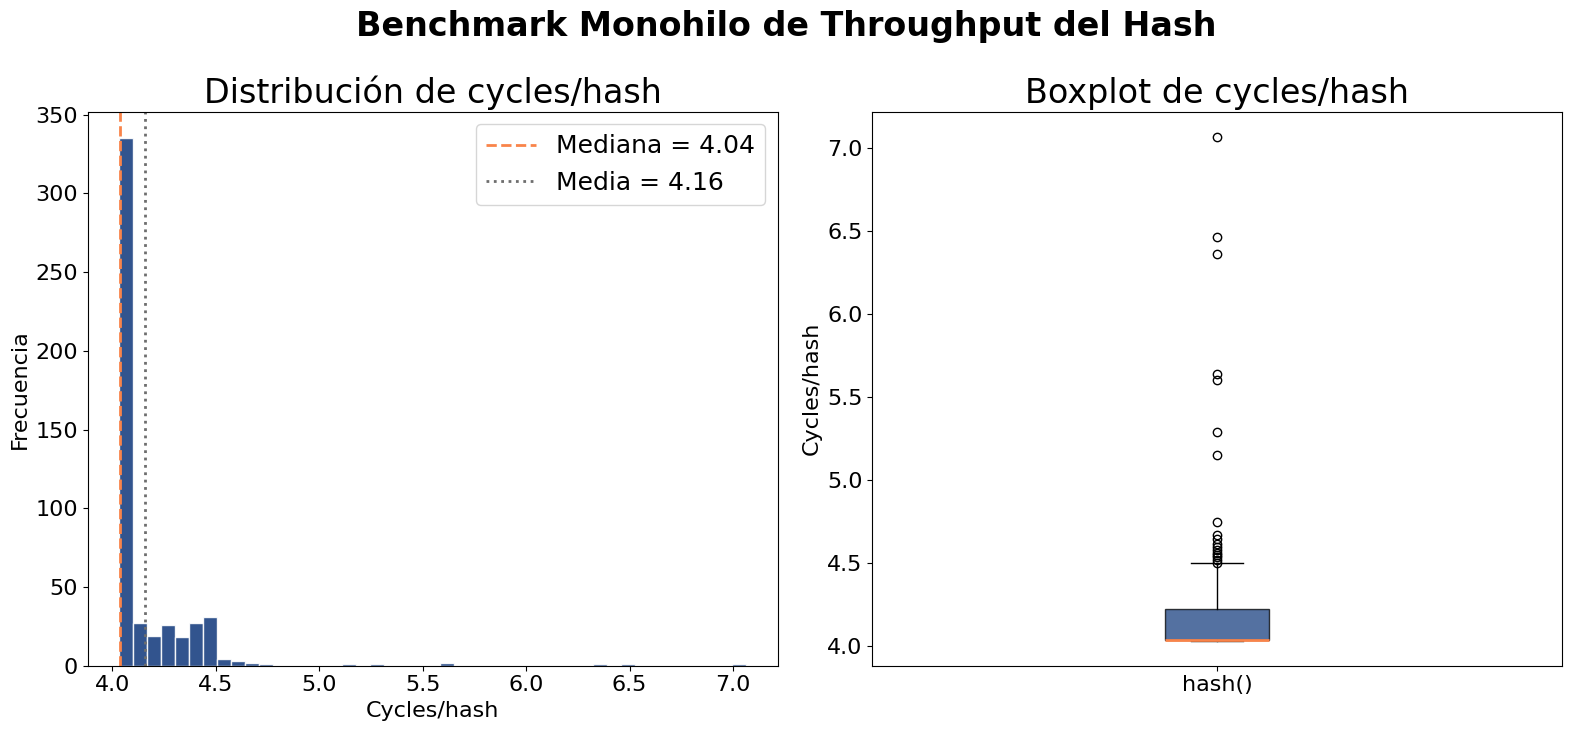

In [61]:
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE)

axes[0].hist(tp_cycles_per_rep, bins="auto", color=COLOR_BLUE, edgecolor="white", alpha=0.9)
axes[0].axvline(tp_median, color=COLOR_ORANGE, linestyle="--", linewidth=2, label=f"Mediana = {tp_median:.2f}")
axes[0].axvline(tp_mean, color=GRAY_DARK, linestyle=":", linewidth=2, label=f"Media = {tp_mean:.2f}")
axes[0].set_title("Distribución de cycles/hash")
axes[0].set_xlabel("Cycles/hash")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()

axes[1].boxplot(
    tp_cycles_per_rep,
    vert=True,
    patch_artist=True,
    boxprops={"facecolor": COLOR_BLUE, "alpha": 0.75},
    medianprops={"color": COLOR_ORANGE, "linewidth": 2},
)
axes[1].set_title("Boxplot de cycles/hash")
axes[1].set_ylabel("Cycles/hash")
axes[1].set_xticks([1])
axes[1].set_xticklabels(["hash()"])

fig.suptitle("Benchmark Monohilo de Throughput del Hash", fontweight='bold')
fig.tight_layout()
plt.show()

#### 4.3.2 Estabilidad entre Repeticiones

Comprobación de deriva temporal y outliers aislados en las mediciones.

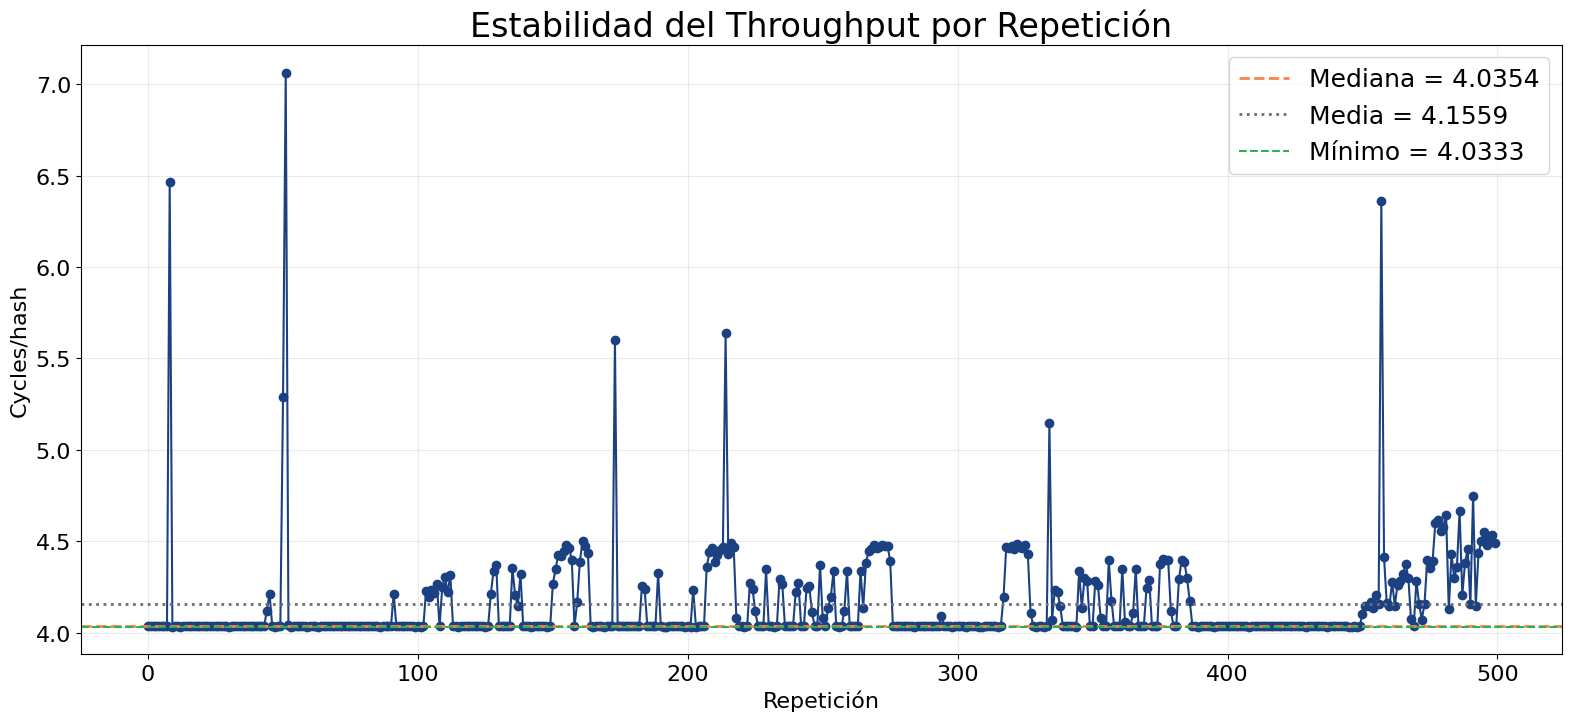

In [62]:
fig, ax = plt.subplots(figsize=FIGSIZE)

ax.plot(tp_rep_ids, tp_cycles_per_rep, marker="o", linewidth=1.5, color=COLOR_BLUE)
ax.axhline(tp_median, color=COLOR_ORANGE, linestyle="--", linewidth=2, label=f"Mediana = {tp_median:.4f}")
ax.axhline(tp_mean, color=GRAY_DARK, linestyle=":", linewidth=2, label=f"Media = {tp_mean:.4f}")
ax.axhline(tp_min, color=COLOR_GREEN, linestyle="--", linewidth=1.5, label=f"Mínimo = {tp_min:.4f}")

ax.set_title("Estabilidad del Throughput por Repetición")
ax.set_xlabel("Repetición")
ax.set_ylabel("Cycles/hash")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()